In [24]:
import random
import shutil
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib import colors as mcolors
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from torch import nn
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms

In [25]:
SEED = 42
BATCH_SIZE = 128
EPOCHS = 8
LR = 0.01
MOMENTUM = 0.9
NUM_WORKERS = 2
from google.colab import drive
drive.mount('/content/drive')
PREFERRED_ARCHIVES = [
    Path('/content/drive/MyDrive/Datasets/notMNIST_large.zip.zip'),
    Path('notMNIST_large.zip'),
]
DATA_ROOT = Path('data/notmnist')
EXTRACTED_BASE = DATA_ROOT / 'extracted'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
def fix_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def pick_archive_path() -> Path:
    for path in PREFERRED_ARCHIVES:
        if path.exists():
            return path
    names = ', '.join(str(p) for p in PREFERRED_ARCHIVES)
    raise FileNotFoundError(f'Не найден архив notMNIST. Ожидались файлы: {names}')


def find_notmnist_root(search_root: Path) -> Path:
    candidates = []
    for d in search_root.rglob('*'):
        if not d.is_dir():
            continue
        class_dirs = sorted([x.name for x in d.iterdir() if x.is_dir()])
        if len(class_dirs) < 10:
            continue
        if all(len(name) == 1 and name.isalpha() for name in class_dirs[:10]):
            candidates.append((d, class_dirs))
    if len(candidates) == 0:
        raise RuntimeError(f'Не найден корень notMNIST внутри {search_root.resolve()}')
    for d, class_dirs in candidates:
        if 'A' in class_dirs and 'J' in class_dirs:
            return d
    return candidates[0][0]


def prepare_notmnist() -> Path:
    archive_path = pick_archive_path()
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    if not zipfile.is_zipfile(archive_path):
        raise RuntimeError(
            f'Архив {archive_path.name} пока невалидный. '
            f'Скорее всего, загрузка не завершена. Дождись окончания и запусти снова.'
        )

    archive_tag = archive_path.name.replace('.zip.zip', '').replace('.zip', '')
    extracted_dir = EXTRACTED_BASE / archive_tag
    inner_archive = extracted_dir / 'notMNIST_inner.zip'

    if not extracted_dir.exists():
        extracted_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive_path, 'r') as zf:
            names = zf.namelist()
            if len(names) == 0:
                raise RuntimeError(f'Архив {archive_path.name} пустой')
            if len(names) == 1 and names[0].lower().endswith('.zip'):
                with zf.open(names[0]) as src, open(inner_archive, 'wb') as dst:
                    shutil.copyfileobj(src, dst)
                if not zipfile.is_zipfile(inner_archive):
                    raise RuntimeError('Внутренний архив notMNIST повреждён')
                with zipfile.ZipFile(inner_archive, 'r') as inner_zf:
                    inner_zf.extractall(extracted_dir)
            else:
                zf.extractall(extracted_dir)

    dataset_root = find_notmnist_root(extracted_dir)
    return dataset_root

In [27]:
class NotMNISTDataset(Dataset):
    def __init__(self, root_dir: Path, transform=None):
        self.root_dir = Path(root_dir)
        self.transform = transform
        self.class_names = sorted([
            d.name for d in self.root_dir.iterdir()
            if d.is_dir() and len(d.name) == 1 and d.name.isalpha()
        ])
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}
        self.samples = []
        self.skipped_files = []
        for class_name in self.class_names:
            class_dir = self.root_dir / class_name
            label = self.class_to_idx[class_name]
            for img_path in sorted(class_dir.iterdir()):
                if img_path.suffix.lower() not in ('.png', '.jpg', '.jpeg', '.bmp', '.gif'):
                    continue
                if self.is_valid_image(img_path):
                    self.samples.append((img_path, label))
                else:
                    self.skipped_files.append(img_path)
        print(f"Датасет загружен: {len(self.samples)} изображений, "
              f"пропущено битых: {len(self.skipped_files)}")
    @staticmethod
    def is_valid_image(image_path: Path) -> bool:
        try:
            with Image.open(image_path) as img:
                img.verify()
            return True
        except (UnidentifiedImageError, Exception):
            return False
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        try:
            img = Image.open(img_path).convert('L')
        except Exception:
            img = Image.new('L', (28, 28), 0)
        if self.transform:
            img = self.transform(img)
        return img, label

In [28]:
def split_dataset(dataset: Dataset, seed: int):
    total = len(dataset)
    n_train = int(total * 0.7)
    n_val = int(total * 0.15)
    n_test = total - n_train - n_val

    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(total, generator=generator).tolist()

    train_idx = indices[:n_train]
    val_idx = indices[n_train:n_train + n_val]
    test_idx = indices[n_train + n_val:]

    return Subset(dataset, train_idx), Subset(dataset, val_idx), Subset(dataset, test_idx)

In [29]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.classifier(x)
        return x

In [30]:
def train_one_epoch(model, loader, optimizer, criterion, device, num_classes):
    model.train()

    total_loss = 0.0
    all_preds  = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)      # взвешиваем на размер батча
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss  = total_loss / len(loader.dataset)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    recall    = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    return avg_loss, precision, recall


def eval_one_epoch(model, loader, criterion, device, num_classes):
    model.eval()

    total_loss = 0.0
    all_preds  = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss   = criterion(logits, labels)

            total_loss += loss.item() * images.size(0)
            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    avg_loss  = total_loss / len(loader.dataset)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    recall    = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    cm        = confusion_matrix(all_labels, all_preds, labels=list(range(num_classes)))
    return avg_loss, precision, recall, torch.tensor(cm)

In [31]:
def show_confusion_matrix(confusion: torch.Tensor, class_names):
    cm = confusion.numpy().astype(np.float64)
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm), where=row_sums != 0) * 100.0
    cm_err = cm.copy()
    np.fill_diagonal(cm_err, 0.0)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    ticks = np.arange(len(class_names))

    im0 = axes[0].imshow(cm_norm, interpolation='nearest', cmap='YlGnBu', vmin=0, vmax=max(5.0, float(cm_norm.max())))
    axes[0].set_title('Confusion Matrix, % по истинному классу')
    axes[0].set_xticks(ticks)
    axes[0].set_xticklabels(class_names)
    axes[0].set_yticks(ticks)
    axes[0].set_yticklabels(class_names)
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')
    fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

    err_max = float(cm_err.max())
    if err_max > 0:
        masked = np.ma.masked_where(cm_err <= 0, cm_err)
        im1 = axes[1].imshow(masked, interpolation='nearest', cmap='OrRd', norm=mcolors.LogNorm(vmin=1, vmax=err_max))
        fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
    else:
        axes[1].imshow(cm_err, interpolation='nearest', cmap='OrRd')

    axes[1].set_title('Только ошибки (без диагонали, log scale)')
    axes[1].set_xticks(ticks)
    axes[1].set_xticklabels(class_names)
    axes[1].set_yticks(ticks)
    axes[1].set_yticklabels(class_names)
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('True')

    plt.tight_layout()
    plt.show()

In [32]:
def show_wrong_examples(model, loader, class_names, device, max_items=12):
    model.eval()
    images_all = []
    y_true_all = []
    y_pred_all = []
    conf_all = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            logits = model(images)
            probs = torch.softmax(logits, dim=1)
            conf, preds = probs.max(dim=1)
            images_all.append(images.cpu())
            y_true_all.append(labels)
            y_pred_all.append(preds.cpu())
            conf_all.append(conf.cpu())

    images_all = torch.cat(images_all, dim=0)
    y_true_all = torch.cat(y_true_all, dim=0)
    y_pred_all = torch.cat(y_pred_all, dim=0)
    conf_all = torch.cat(conf_all, dim=0)

    wrong_idx = (y_true_all != y_pred_all).nonzero(as_tuple=False).squeeze(1)
    if wrong_idx.numel() == 0:
        print('На тесте ошибок не найдено, примеры ошибочных предсказаний отсутствуют.')
        return

    wrong_conf = conf_all[wrong_idx]
    order = torch.argsort(wrong_conf, descending=True)
    selected_idx = wrong_idx[order][:max_items]

    n = len(selected_idx)
    cols = 4
    rows = (n + cols - 1) // cols
    plt.figure(figsize=(12, 3 * rows))

    for i in range(n):
        idx = int(selected_idx[i])
        plt.subplot(rows, cols, i + 1)
        img = images_all[idx].squeeze(0).numpy()
        true_name = class_names[int(y_true_all[idx])]
        pred_name = class_names[int(y_pred_all[idx])]
        conf = float(conf_all[idx])
        plt.imshow(img, cmap='gray')
        plt.title(f'истинный: {true_name} | пред: {pred_name} | p={conf:.2f}')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

In [33]:
def report_top_confusions_and_examples(confusion: torch.Tensor, class_names, model, test_loader, device):
    cm = confusion.numpy().copy().astype(float)
    np.fill_diagonal(cm, 0)
    flat      = cm.flatten()
    top10_idx = np.argsort(flat)[::-1][:10]

    print("=== Топ-10 самых частых путаниц (true → pred : count) ===")
    top_pairs = []
    for idx in top10_idx:
        true_cls = idx // len(class_names)
        pred_cls = idx % len(class_names)
        count    = int(cm[true_cls, pred_cls])
        if count == 0:
            break
        print(f"  {class_names[true_cls]} → {class_names[pred_cls]} : {count}")
        top_pairs.append((true_cls, pred_cls, count))
    model.eval()
    images_all, y_true_all, y_pred_all = [], [], []

    with torch.no_grad():
        for images, labels in test_loader:
            preds = model(images.to(device)).argmax(dim=1).cpu()
            images_all.append(images)
            y_true_all.append(labels)
            y_pred_all.append(preds)

    images_all = torch.cat(images_all)
    y_true_all = torch.cat(y_true_all)
    y_pred_all = torch.cat(y_pred_all)
    for true_cls, pred_cls, count in top_pairs[:3]:
        mask   = (y_true_all == true_cls) & (y_pred_all == pred_cls)
        subset = images_all[mask][:6]
        if len(subset) == 0:
            continue

        n = len(subset)
        _, axes = plt.subplots(1, n, figsize=(2.5 * n, 2.5))
        if n == 1:
            axes = [axes]

        plt.suptitle(
            f"Истинный: '{class_names[true_cls]}'  →  "
            f"Предсказан: '{class_names[pred_cls]}'  (всего ошибок: {count})",
            fontsize=11, y=1.02
        )
        for ax, img in zip(axes, subset):
            ax.imshow(img.squeeze(0).numpy(), cmap='gray')
            ax.axis('off')
        plt.tight_layout()
        plt.show()
# Что можно сделать:
#   - Аугментации: случайное увеличение (RandomResizedCrop) поможет
#     модели лучше видеть мелкие детали.
#   - Focal Loss вместо CrossEntropy — штрафует сильнее за уверенные
#     неправильные предсказания на «похожих» классах.
#   - Hard Negative Mining — дообучение на парах, которые путаются чаще.

In [23]:
fix_seed(SEED)
data_dir = prepare_notmnist()

transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

dataset = NotMNISTDataset(root_dir=data_dir, transform=transform)
train_dataset, val_dataset, test_dataset = split_dataset(dataset, SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_classes = len(dataset.class_names)

model = SimpleCNN(num_classes=num_classes).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM)
criterion = nn.CrossEntropyLoss()

Датасет загружен: 529114 изображений, пропущено битых: 5


In [34]:
history = []
for epoch in range(1, EPOCHS + 1):
    train_loss, train_prec, train_rec = train_one_epoch(
        model, train_loader, optimizer, criterion, device, num_classes
    )
    val_loss, val_prec, val_rec, _ = eval_one_epoch(
        model, val_loader, criterion, device, num_classes
    )

    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'train_precision': train_prec,
        'train_recall': train_rec,
        'val_loss': val_loss,
        'val_precision': val_prec,
        'val_recall': val_rec,
    })

    print(
        f'epoch={epoch} | train_loss={train_loss:.4f} | train_precision={train_prec:.4f} | '
        f'train_recall={train_rec:.4f} | val_loss={val_loss:.4f} | '
        f'val_precision={val_prec:.4f} | val_recall={val_rec:.4f}'
    )

test_loss, test_prec, test_rec, test_confusion = eval_one_epoch(
    model, test_loader, criterion, device, num_classes
)
print(f'test_loss={test_loss:.4f} | test_precision={test_prec:.4f} | test_recall={test_rec:.4f}')

epoch=1 | train_loss=0.3388 | train_precision=0.8993 | train_recall=0.8990 | val_loss=0.2841 | val_precision=0.9147 | val_recall=0.9134
epoch=2 | train_loss=0.2497 | train_precision=0.9239 | train_recall=0.9236 | val_loss=0.2513 | val_precision=0.9246 | val_recall=0.9239
epoch=3 | train_loss=0.2206 | train_precision=0.9323 | train_recall=0.9320 | val_loss=0.2412 | val_precision=0.9271 | val_recall=0.9261
epoch=4 | train_loss=0.2006 | train_precision=0.9376 | train_recall=0.9374 | val_loss=0.2348 | val_precision=0.9298 | val_recall=0.9285
epoch=5 | train_loss=0.1838 | train_precision=0.9426 | train_recall=0.9425 | val_loss=0.2289 | val_precision=0.9315 | val_recall=0.9312
epoch=6 | train_loss=0.1689 | train_precision=0.9472 | train_recall=0.9471 | val_loss=0.2366 | val_precision=0.9326 | val_recall=0.9314
epoch=7 | train_loss=0.1557 | train_precision=0.9512 | train_recall=0.9511 | val_loss=0.2283 | val_precision=0.9329 | val_recall=0.9321
epoch=8 | train_loss=0.1429 | train_precision=0.

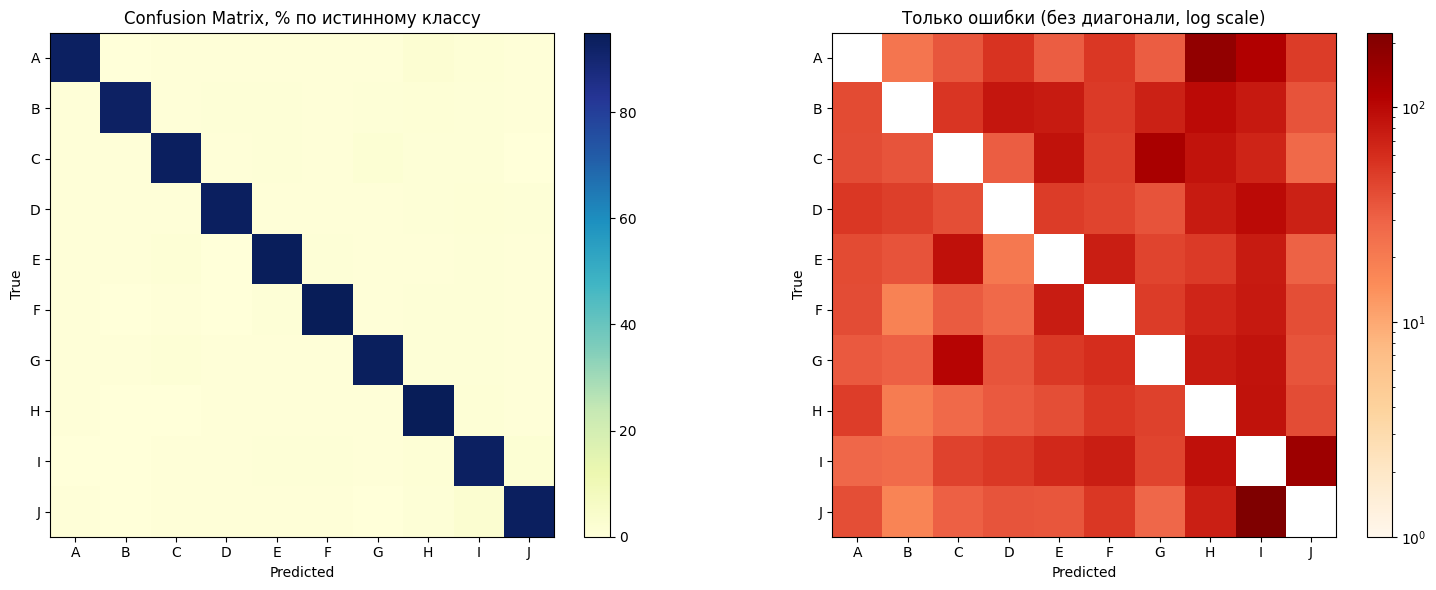

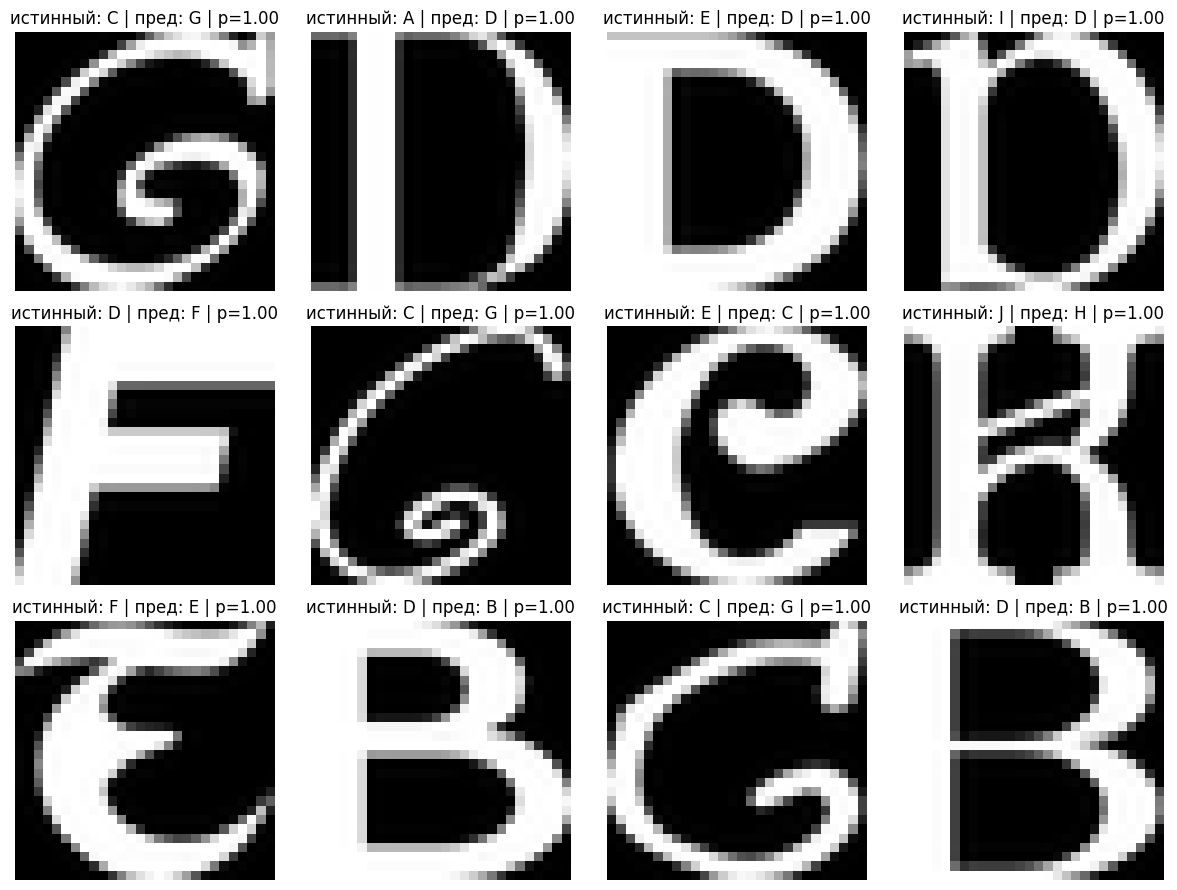

=== Топ-10 самых частых путаниц (true → pred : count) ===
  J → I : 223
  A → H : 172
  I → J : 147
  C → G : 127
  A → I : 114
  G → C : 106
  D → I : 96
  B → H : 96
  I → H : 89
  E → C : 89


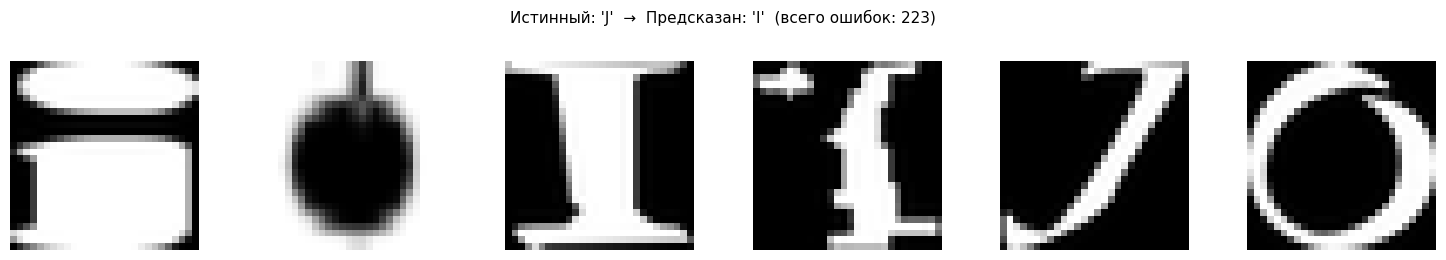

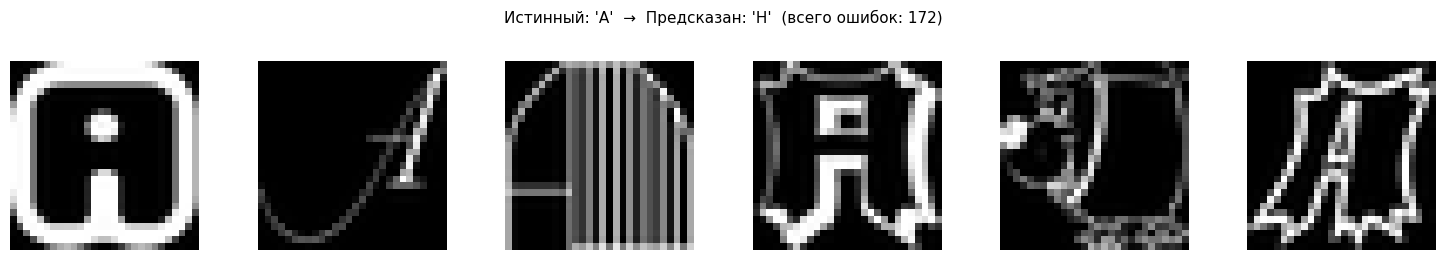

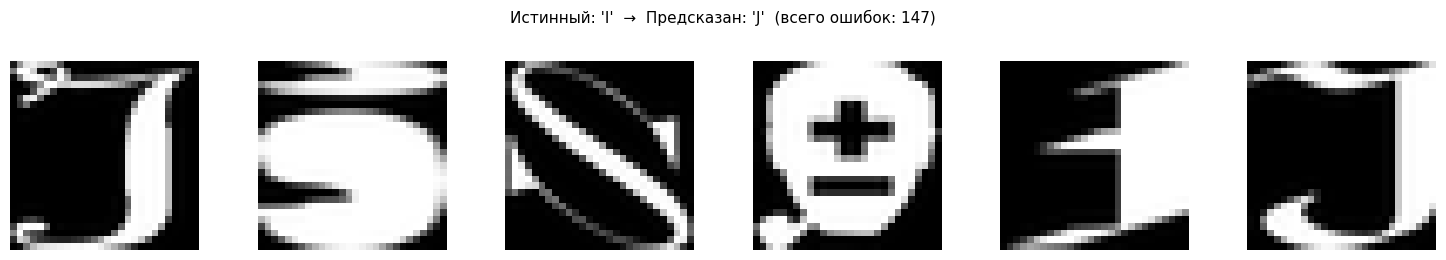

In [ ]:
show_confusion_matrix(test_confusion, dataset.class_names)
show_wrong_examples(model, test_loader, dataset.class_names, device, max_items=12)
report_top_confusions_and_examples(test_confusion, dataset.class_names, model, test_loader, device)